# The valid address was rejected: ten email validators against the RFC

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phoebefu6/phoebe-the-builder/blob/main/data-quality-governance/email-validator/demo.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/phoebefu6/phoebe-the-builder/main?labpath=data-quality-governance/email-validator/demo.ipynb)

A customer called O'Brien cannot sign up, and a support ticket says the form called a real address invalid. This
notebook runs ten validators people actually paste into code against a reference parser for RFC 5321 (SMTP) and
RFC 6531 (international addresses), over 68 hand-labelled addresses.

1. The engine
2. The scoreboard
3. Which real customers each one turns away
4. The overlap: what every validator gets wrong together
5. The chart
6. Try your own

## 1. The engine

Extracted from `explore.py` and `evidence.py` at build time. `reference` sorts an address into **ok** (deliverable),
**grey** (valid by the grammar but local-only: `user@localhost`, an IP literal, a numeric TLD) or **bad**. Every
corpus row also carries a hand label, and the two agree on all 68. Regexes are applied the way they are pasted:
`re.match` on a `^...$` pattern. Nothing is random, so every number below matches `evidence.txt` exactly.

In [1]:
from __future__ import annotations

# !pip install email-validator==2.3.0   # uncomment on Colab / Binder
import ipaddress
import re
import string
from email.utils import parseaddr
from typing import Callable, Dict, List, Tuple

import matplotlib.pyplot as plt
from email_validator import EmailNotValidError, validate_email


class _E:  # evidence.py refers to the engine as E
    pass

ATEXT = set(string.ascii_letters + string.digits + "!#$%&'*+-/=?^_`{|}~")


LDH = set(string.ascii_letters + string.digits + "-")


def _atext(ch: str) -> bool:
    return ch in ATEXT or ord(ch) > 127  # RFC 6531 adds UTF8-non-ascii to atext


def _dot_string(s: str) -> bool:
    return all(p and all(_atext(c) for c in p) for p in s.split("."))


def _quoted_string(s: str) -> bool:
    if len(s) < 2 or s[0] != '"' or s[-1] != '"':
        return False
    body, i = s[1:-1], 0
    while i < len(body):
        o = ord(body[i])
        if body[i] == "\\":  # quoted-pairSMTP = "\" %d32-126
            if i + 1 >= len(body) or not 32 <= ord(body[i + 1]) <= 126:
                return False
            i += 2
            continue
        if not (o in (32, 33) or 35 <= o <= 91 or 93 <= o <= 126 or o > 127):
            return False
        i += 1
    return True


def _label(lab: str) -> bool:
    if any(ord(c) > 127 for c in lab):  # U-label: must survive IDNA encoding to a valid A-label
        try:
            lab = lab.encode("idna").decode("ascii")
        except UnicodeError:
            return False
    return 0 < len(lab) <= 63 and all(c in LDH for c in lab) and lab[0] != "-" and lab[-1] != "-"


def _literal(d: str) -> bool:
    inner = d[1:-1]
    if inner.startswith("IPv6:"):
        try:
            ipaddress.IPv6Address(inner[5:])
            return True
        except ValueError:
            return False
    parts = inner.split(".")
    return len(parts) == 4 and all(p.isdigit() and len(p) <= 3 and int(p) <= 255 for p in parts)


def reference(addr: str) -> Tuple[str, str]:
    """Return (tier, reason). tier is 'ok', 'grey' or 'bad'."""
    if "@" not in addr:
        return "bad", "no @"
    local, domain = addr.rsplit("@", 1)  # a quoted local part may itself contain @
    if not local:
        return "bad", "empty local part"
    if not (_dot_string(local) or _quoted_string(local)):
        return "bad", "local part not a dot-string or quoted-string"
    if len(local.encode()) > 64:
        return "bad", "local part over 64 octets"
    if len(addr.encode()) > 254:
        return "bad", "address over 254 octets"
    if domain.startswith("[") and domain.endswith("]"):
        return ("grey", "address literal") if _literal(domain) else ("bad", "malformed address literal")
    labels = domain.split(".")
    if not domain or not all(_label(x) for x in labels):
        return "bad", "domain label invalid"
    if len(labels) == 1:
        return "grey", "dotless domain"
    if labels[-1].isdigit():
        return "grey", "all-numeric TLD"
    return "ok", "valid"


L64 = "a" * 64


CORPUS: List[Tuple[str, str, str]] = [
    ("john.smith@example.com", "plain", "ok"),
    ("jane@example.org", "plain", "ok"),
    ("a.b.c@company.co.uk", "plain", "ok"),
    ("j@e.co", "plain", "ok"),
    ("first_last@example.com", "plain", "ok"),
    ("info@3m.com", "plain", "ok"),
    ("john+news@gmail.com", "plus tag", "ok"),
    ("j.smith+billing@company.com", "plus tag", "ok"),
    ("anna@mail.eng.example.com", "subdomain", "ok"),
    ("ops@eu-west.corp.example.net", "subdomain", "ok"),
    ("kim@my-company.com", "hyphen in domain", "ok"),
    ("kim@a-b-c.co.uk", "hyphen in domain", "ok"),
    ("lee@studio.photography", "long TLD", "ok"),
    ("lee@firm.technology", "long TLD", "ok"),
    ("nina@art.museum", "long TLD", "ok"),
    ("John.Smith@Example.COM", "uppercase", "ok"),
    ("ANNA@EXAMPLE.ORG", "uppercase", "ok"),
    ("o'brien@example.ie", "apostrophe", "ok"),
    ("d'angelo@example.it", "apostrophe", "ok"),
    ("user!tag@example.com", "other legal symbol", "ok"),
    ("a/b@example.com", "other legal symbol", "ok"),
    ("x=y@example.com", "other legal symbol", "ok"),
    ("user#1@example.com", "other legal symbol", "ok"),
    ("{a}@example.com", "other legal symbol", "ok"),
    ("~home@example.com", "other legal symbol", "ok"),
    ("user&co@example.com", "other legal symbol", "ok"),
    ("-x@example.com", "other legal symbol", "ok"),
    (L64 + "@example.com", "at the length limit", "ok"),
    ("x@" + ".".join(["a" * 63] * 3) + "." + "b" * 56 + ".com", "at the length limit", "ok"),
    ('"john smith"@example.com', "quoted local part", "ok"),
    ('"john..doe"@example.com', "quoted local part", "ok"),
    ('"a@b"@example.com', "quoted local part", "ok"),
    ("josé@example.com", "international (SMTPUTF8)", "ok"),
    ("user@münchen.de", "international (SMTPUTF8)", "ok"),
    ("用户@例子.广告", "international (SMTPUTF8)", "ok"),
    ("user@xn--mnchen-3ya.de", "international (SMTPUTF8)", "ok"),
    # grey: valid by the grammar, not deliverable on the public internet
    ("user@localhost", "dotless host", "grey"),
    ("admin@mailserver1", "dotless host", "grey"),
    ("user@[192.168.1.1]", "IP literal", "grey"),
    ("user@[IPv6:2001:db8::1]", "IP literal", "grey"),
    ("user@example.123", "numeric TLD", "grey"),
    # bad: not a valid mailbox
    ("john.example.com", "no @ / two @", "bad"),
    ("a@b@example.com", "no @ / two @", "bad"),
    ("@example.com", "empty part", "bad"),
    ("john@", "empty part", "bad"),
    (".john@example.com", "dot misuse", "bad"),
    ("john.@example.com", "dot misuse", "bad"),
    ("john..doe@example.com", "dot misuse", "bad"),
    ("john@example..com", "dot misuse", "bad"),
    ("john@example.com.", "dot misuse", "bad"),
    ("john doe@example.com", "space / control char", "bad"),
    ("john@example.com\n", "space / control char", "bad"),
    ("john\t@example.com", "space / control char", "bad"),
    ("john@-example.com", "bad domain label", "bad"),
    ("john@example-.com", "bad domain label", "bad"),
    ("john@ex_ample.com", "bad domain label", "bad"),
    ("john@" + "a" * 64 + ".com", "over a length limit", "bad"),
    ("a" + L64 + "@example.com", "over a length limit", "bad"),
    ("x@" + ".".join(["a" * 63] * 3) + "." + "b" * 57 + ".com", "over a length limit", "bad"),
    ('"john@example.com', "broken quoting", "bad"),
    ('"a"b"@example.com', "broken quoting", "bad"),
    ('john."doe"@example.com', "broken quoting", "bad"),
    ("john,doe@example.com", "illegal symbol", "bad"),
    ("john[1]@example.com", "illegal symbol", "bad"),
    ("john(work)@example.com", "RFC 5322 header syntax", "bad"),
    ("<john@example.com>", "RFC 5322 header syntax", "bad"),
    ("John <john@example.com>", "RFC 5322 header syntax", "bad"),
    ("user@[300.1.1.1]", "malformed IP literal", "bad"),
]


SHARE: Dict[str, float] = {
    "plain": 0.880,
    "plus tag": 0.030,
    "subdomain": 0.020,
    "hyphen in domain": 0.020,
    "long TLD": 0.015,
    "uppercase": 0.020,
    "apostrophe": 0.003,
    "other legal symbol": 0.001,
    "at the length limit": 0.0005,
    "quoted local part": 0.0001,
    "international (SMTPUTF8)": 0.0104,
}


P_SIMPLE = r"^\S+@\S+\.\S+$"


P_TUTORIAL = r"^[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}$"


P_STRICT = r"^[a-zA-Z0-9_.]+@[a-zA-Z0-9]+\.[a-zA-Z]{2,4}$"


P_OWASP = r"^[a-zA-Z0-9_+&*-]+(?:\.[a-zA-Z0-9_+&*-]+)*@(?:[a-zA-Z0-9-]+\.)+[a-zA-Z]{2,7}$"


P_HTML5 = (
    r"^[a-zA-Z0-9.!#$%&'*+/=?^_`{|}~-]+@[a-zA-Z0-9](?:[a-zA-Z0-9-]{0,61}[a-zA-Z0-9])?"
    r"(?:\.[a-zA-Z0-9](?:[a-zA-Z0-9-]{0,61}[a-zA-Z0-9])?)*$"
)


P_5322 = (
    r"^(?:[a-z0-9!#$%&'*+/=?^_`{|}~-]+(?:\.[a-z0-9!#$%&'*+/=?^_`{|}~-]+)*|\"(?:[\x01-\x08\x0b\x0c\x0e-\x1f\x21"
    r"\x23-\x5b\x5d-\x7f]|\\[\x01-\x09\x0b\x0c\x0e-\x7f])*\")@(?:(?:[a-z0-9](?:[a-z0-9-]*[a-z0-9])?\.)+[a-z0-9]"
    r"(?:[a-z0-9-]*[a-z0-9])?|\[(?:(?:25[0-5]|2[0-4][0-9]|[01]?[0-9][0-9]?)\.){3}(?:25[0-5]|2[0-4][0-9]|[01]?"
    r"[0-9][0-9]?|[a-z0-9-]*[a-z0-9]:(?:[\x01-\x08\x0b\x0c\x0e-\x1f\x21-\x5a\x53-\x7f]|\\[\x01-\x09\x0b\x0c\x0e-"
    r"\x7f])+)\])$"
)


def _rx(p: str, flags: int = 0) -> Callable[[str], bool]:
    rx = re.compile(p, flags)
    return lambda s: rx.match(s) is not None


def _handrolled(s: str) -> bool:
    if s.count("@") != 1 or " " in s:
        return False
    local, domain = s.split("@")
    return bool(local) and "." in domain and not domain.startswith(".") and not domain.endswith(".")


def _library(s: str) -> bool:
    try:
        validate_email(s, check_deliverability=False)
        return True
    except EmailNotValidError:
        return False


VALIDATORS: Dict[str, Callable[[str], bool]] = {
    "contains @": lambda s: "@" in s,
    "hand-rolled split": _handrolled,
    "\\S+@\\S+\\.\\S+": _rx(P_SIMPLE),
    "tutorial regex": _rx(P_TUTORIAL),
    "strict TLD{2,4}": _rx(P_STRICT),
    "OWASP regex": _rx(P_OWASP),
    "HTML5 type=email": _rx(P_HTML5),
    "RFC 5322 regex": _rx(P_5322, re.I),
    "stdlib parseaddr": lambda s: "@" in parseaddr(s)[1],
    "email-validator 2.3": _library,
}


def score(name: str, share: Dict[str, float] = SHARE) -> Dict:
    """False rejects (ok rejected), false accepts (bad accepted), grey accepted, and sign-ups lost under `share`."""
    f = VALIDATORS[name]
    rows = [(a, g, reference(a)[0], f(a)) for a, g, _ in CORPUS]
    per_group = {g: sum(1 for _, gg, t, _ in rows if gg == g) for g in share}
    lost = sum(share[g] / per_group[g] for _, g, t, acc in rows if t == "ok" and not acc)
    return {
        "false_reject": [a for a, _, t, acc in rows if t == "ok" and not acc],
        "false_accept": [a for a, _, t, acc in rows if t == "bad" and acc],
        "grey_accept": [a for a, _, t, acc in rows if t == "grey" and acc],
        "groups_rejected": sorted({g for _, g, t, acc in rows if t == "ok" and not acc}),
        "groups_accepted_bad": sorted({g for _, g, t, acc in rows if t == "bad" and acc}),
        "signups_lost": lost / sum(share.values()),
    }


def chain(names: List[str]) -> Callable[[str], bool]:
    """A sign-up form usually stacks validators (browser, API, database). An address must pass every one."""
    return lambda s: all(VALIDATORS[n](s) for n in names)


def study(share: Dict[str, float] = SHARE) -> Dict:
    tiers = {t: sum(1 for a, _, _ in CORPUS if reference(a)[0] == t) for t in ("ok", "grey", "bad")}
    per = {n: score(n, share) for n in VALIDATORS}
    ok = [a for a, _, _ in CORPUS if reference(a)[0] == "ok"]
    bad = [a for a, _, _ in CORPUS if reference(a)[0] == "bad"]
    names = list(VALIDATORS)
    stack = ["HTML5 type=email", "tutorial regex", "email-validator 2.3"]
    together = chain(stack)
    return {
        "tiers": tiers,
        "per": per,
        "rejected_by_none": [a for a in ok if all(VALIDATORS[n](a) for n in names)],
        "ok_rejected_by_k": {a: sum(not VALIDATORS[n](a) for n in names) for a in ok},
        "bad_accepted_by_k": {a: sum(VALIDATORS[n](a) for n in names) for a in bad},
        "perfect": [n for n in names if not per[n]["false_reject"] and not per[n]["false_accept"]],
        "stack": stack,
        "stack_false_reject": [a for a in ok if not together(a)],
        "stack_signups_lost": sum(
            share[g] / sum(1 for _, gg, _ in CORPUS if gg == g)
            for a, g, _ in CORPUS
            if reference(a)[0] == "ok" and not together(a)
        )
        / sum(share.values()),
        "newline_accepted_by": [n for n in names if VALIDATORS[n]("john@example.com\n")],
    }


E = _E()
E.__dict__.update(globals())

def show(a: str) -> str:
    return repr(a) if len(a) <= 40 else repr(a[:18] + "..." + a[-14:]) + f" ({len(a.encode())} octets)"


def lines(r: dict) -> List[str]:
    out: List[str] = []
    w = out.append
    t = r["tiers"]
    w(
        f"email-validator evidence  ({len(E.CORPUS)} addresses: {t['ok']} deliverable, {t['grey']} valid-but-local, "
        f"{t['bad']} invalid; truth = RFC 5321 + RFC 6531 reference parser, agreeing with a hand label on every row; "
        f"no randomness, every number exact)"
    )
    w("")
    w("1. Each validator against the reference (FR = deliverable rejected, FA = invalid accepted)")
    w(f"{'validator':<22} {'FR':>3} {'FA':>3} {'grey ok':>8} {'sign-ups lost':>14}")
    for n, p in r["per"].items():
        w(
            f"{n:<22} {len(p['false_reject']):>3} {len(p['false_accept']):>3} {len(p['grey_accept']):>8} "
            f"{p['signups_lost']:>14.2%}"
        )
    w("")
    w("2. Which deliverable groups each validator rejects")
    for n, p in r["per"].items():
        w(f"{n:<22} {', '.join(p['groups_rejected']) or '-'}")
    w("")
    w("3. Deliverable addresses rejected by the most validators (of 10)")
    for a, k in sorted(r["ok_rejected_by_k"].items(), key=lambda x: -x[1])[:8]:
        w(f"{k:>2}  {show(a)}")
    w("")
    w("4. Invalid addresses accepted by the most validators (of 10)")
    for a, k in sorted(r["bad_accepted_by_k"].items(), key=lambda x: -x[1])[:8]:
        w(f"{k:>2}  {show(a)}  ({E.reference(a)[1]})")
    w("")
    w("5. The overlap")
    w(f"validators with zero errors: {len(r['perfect'])}")
    w(f"accept 'john@example.com\\n' (trailing newline): {len(r['newline_accepted_by'])} of 10")
    w(
        f"stacked {' + '.join(r['stack'])}: rejects {len(r['stack_false_reject'])} deliverable addresses, "
        f"{r['stack_signups_lost']:.2%} of sign-ups"
    )
    return out


def main() -> None:
    r = E.study()
    json.dump({"main": r, "share": E.SHARE}, open("results.json", "w"), indent=1, ensure_ascii=False)
    open("evidence.txt", "w").write("\n".join(lines(r)) + "\n")
    print("\n".join(lines(r)))

In [2]:
r = study()
out = lines(r)
section = lambda n: [l for l in "\n".join(out).split(f"\n{n}. ")[1].split("\n\n")[0].splitlines()]
print(out[0])

email-validator evidence  (68 addresses: 36 deliverable, 5 valid-but-local, 27 invalid; truth = RFC 5321 + RFC 6531 reference parser, agreeing with a hand label on every row; no randomness, every number exact)


## 2. The scoreboard

FR counts deliverable addresses rejected (of 36), FA invalid addresses accepted (of 27). `sign-ups lost` weights
each deliverable group by a **declared** share of real sign-ups (88% plain, 3% plus-tags, 1.04% international, and
so on; edit `SHARE`). The most-copied tutorial regex turns away 1.18%; OWASP's 2.16%, because it caps the TLD at
seven letters; an old `{2,4}` TLD regex 24.64%. The library, email-validator 2.3, is closest: 3 FR (all quoted local
parts, by policy) and 1 FA.

In [3]:
print("\n".join(section(1)))

Each validator against the reference (FR = deliverable rejected, FA = invalid accepted)
validator               FR  FA  grey ok  sign-ups lost
contains @               0  26        5          0.00%
hand-rolled split        2  20        2          0.01%
\S+@\S+\.\S+             1  21        2          0.00%
tutorial regex          15  10        0          1.18%
strict TLD{2,4}         28   6        0         24.64%
OWASP regex             16   6        0          2.16%
HTML5 type=email         6   6        3          0.79%
RFC 5322 regex           4   4        2          0.78%
stdlib parseaddr         0  20        3          0.00%
email-validator 2.3      3   1        0          0.01%


## 3. Which real customers each one turns away

The groups each validator refuses. Apostrophes (O'Brien, D'Angelo) and international addresses are the expensive
ones: real people, legal since 2012 (RFC 6531), and refused by five of ten.

In [4]:
print("\n".join(section(2)))
print()
print("\n".join(section(3)))

Which deliverable groups each validator rejects
contains @             -
hand-rolled split      quoted local part
\S+@\S+\.\S+           quoted local part
tutorial regex         apostrophe, international (SMTPUTF8), other legal symbol, quoted local part
strict TLD{2,4}        apostrophe, at the length limit, hyphen in domain, international (SMTPUTF8), long TLD, other legal symbol, plain, plus tag, quoted local part, subdomain
OWASP regex            apostrophe, international (SMTPUTF8), long TLD, other legal symbol, quoted local part
HTML5 type=email       international (SMTPUTF8), quoted local part
RFC 5322 regex         international (SMTPUTF8), quoted local part
stdlib parseaddr       -
email-validator 2.3    quoted local part

Deliverable addresses rejected by the most validators (of 10)
 8  '"john smith"@example.com'
 6  '"a@b"@example.com'
 5  '"john..doe"@example.com'
 5  'josé@example.com'
 5  'user@münchen.de'
 5  '用户@例子.广告'
 3  "o'brien@example.ie"
 3  "d'angelo@example.it"


## 4. The overlap

Zero validators are error-free. A 65-octet local part passes all ten: the library only enforces RFC 5321's 64-octet
limit with `strict=True`. `john@example.com\n` passes 9 of 10, because Python's `$` matches before a final newline:
a header-injection risk, not a typo. Stacking the browser's HTML5 check, the tutorial regex and the library rejects 15
deliverable addresses, 1.18% of sign-ups: a stack is as strict as its strictest member and as loose as nothing.

In [5]:
print("\n".join(section(4)))
print()
print("\n".join(section(5)))

Invalid addresses accepted by the most validators (of 10)
10  'aaaaaaaaaaaaaaaaaa...aa@example.com' (77 octets)  (local part over 64 octets)
 9  'john@example.com\n'  (domain label invalid)
 8  'john@aaaaaaaaaaaaa...aaaaaaaaaa.com' (73 octets)  (domain label invalid)
 8  'x@aaaaaaaaaaaaaaaa...bbbbbbbbbb.com' (255 octets)  (address over 254 octets)
 7  '.john@example.com'  (local part not a dot-string or quoted-string)
 7  'john.@example.com'  (local part not a dot-string or quoted-string)
 7  'john..doe@example.com'  (local part not a dot-string or quoted-string)
 6  'john@-example.com'  (domain label invalid)

The overlap
validators with zero errors: 0
accept 'john@example.com\n' (trailing newline): 9 of 10
stacked HTML5 type=email + tutorial regex + email-validator 2.3: rejects 15 deliverable addresses, 1.18% of sign-ups


## 5. The chart

The full figure, with the address taken apart, is `audit.png` (built by `make_chart.py`). Here, the two error counts.

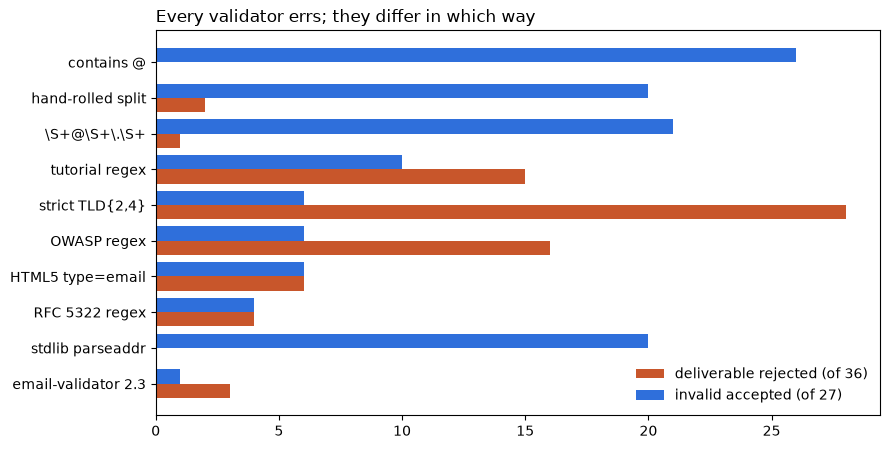

In [6]:
names = list(VALIDATORS)
fr = [len(r["per"][n]["false_reject"]) for n in names]
fa = [len(r["per"][n]["false_accept"]) for n in names]
fig, ax = plt.subplots(figsize=(9, 4.6))
y = range(len(names))
ax.barh([i + 0.2 for i in y], fr, height=0.4, color="#c8562b", label="deliverable rejected (of 36)")
ax.barh([i - 0.2 for i in y], fa, height=0.4, color="#2f6fdb", label="invalid accepted (of 27)")
ax.set_yticks(list(y), names)
ax.invert_yaxis()
ax.set_title("Every validator errs; they differ in which way", loc="left")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig("notebook_chart.png", dpi=120)
plt.show()

## Summary

- The copy-pasted regexes refuse real customers: apostrophes, international addresses, long TLDs, plus-tags.
- The permissive checks (`"@" in s`, `parseaddr`) refuse nobody and accept almost anything, including a display name.
- 9 of 10 accept a trailing newline. Strip and reject control characters before any regex.
- Validate syntax with a maintained library, then confirm the address by sending to it: syntax cannot prove a
  mailbox exists.

## 6. Try your own

In [7]:
# for a in ["first.last@sub.example.travel", "\"weird\"@example.com", "x@[IPv6:::1]"]:
#     print(a, reference(a), {n: f(a) for n, f in VALIDATORS.items()})

---
Part of [phoebe-the-builder](https://github.com/phoebefu6/phoebe-the-builder). The Streamlit version checks your own
addresses and your own sign-up mix: `pip install -r requirements.txt && streamlit run app.py`.